<a href="https://colab.research.google.com/github/adeldj88/uts-pemodelan-simulasi-optimasi-vitamin/blob/main/Optimasi_Biaya_Suplemen_Vitamin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Code UTS Pemodelan Simulasi Optimasi Vitamin**

## Kelompok 1:
- Kanya Kardisa Kanani_2408561016
- I Gede Surya Tanajaya_2408561047
- Ni Putu Nadia Earlyvania Paramhita_2405861115
- Luh Adelia Pratiwi Djelantik_2408561118

## Grafik kendala, daerah layak, dan titik optimal racikan suplemen vitamin

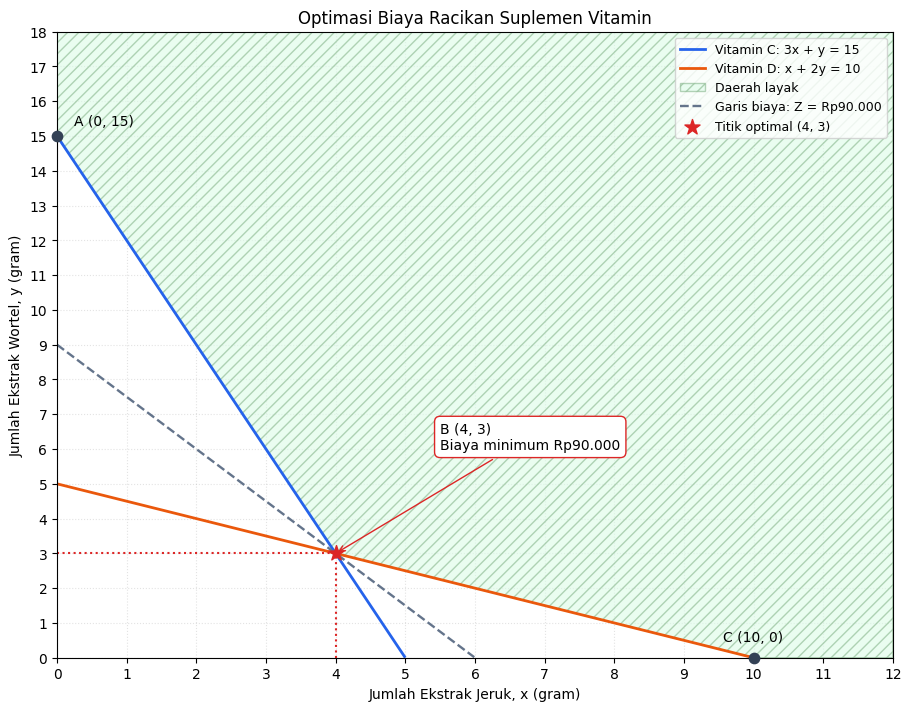

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Rentang jumlah Ekstrak Jeruk
x = np.linspace(0, 12, 600)

# Garis batas kendala
y_c = 15 - 3 * x       # 3x + y = 15
y_d = (10 - x) / 2     # x + 2y = 10

# Batas bawah daerah yang memenuhi seluruh kendala
batas_bawah = np.maximum.reduce([
    y_c, y_d, np.zeros_like(x)
])

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

# Garis batas; hanya tampilkan bagian dengan y nonnegatif
ax.plot(
    x, np.where(y_c >= 0, y_c, np.nan),
    color="#2563EB", linewidth=2,
    label="Vitamin C: 3x + y = 15"
)
ax.plot(
    x, np.where(y_d >= 0, y_d, np.nan),
    color="#EA580C", linewidth=2,
    label="Vitamin D: x + 2y = 10"
)

# Arsiran daerah layak dalam jendela grafik
ax.fill_between(
    x, batas_bawah, 18,
    facecolor="#DCFCE7", edgecolor="#86B58B",
    hatch="///", alpha=0.6,
    label="Daerah layak"
)

# Garis biaya pada nilai optimal
y_biaya = (90000 - 15000 * x) / 10000
ax.plot(
    x, np.where(y_biaya >= 0, y_biaya, np.nan),
    color="#64748B", linestyle="--", linewidth=1.7,
    label="Garis biaya: Z = Rp90.000"
)

# Titik pojok daerah layak
ax.scatter([0, 10], [15, 0], color="#334155", s=55,
           zorder=5, clip_on=False)
ax.annotate(
    "A (0, 15)", (0, 15),
    xytext=(12, 8), textcoords="offset points"
)
ax.annotate(
    "C (10, 0)", (10, 0),
    xytext=(0, 12), textcoords="offset points",
    ha="center"
)

# Titik optimal
ax.scatter(
    4, 3, color="#DC2626", s=130, marker="*",
    zorder=6, label="Titik optimal (4, 3)"
)
ax.annotate(
    "B (4, 3)\nBiaya minimum Rp90.000",
    xy=(4, 3), xytext=(5.5, 6),
    arrowprops=dict(arrowstyle="->", color="#DC2626"),
    bbox=dict(boxstyle="round,pad=0.4",
              facecolor="white", edgecolor="#DC2626"),
    fontsize=10
)

# Garis bantu koordinat titik optimal
ax.plot([4, 4], [0, 3], linestyle=":", color="#DC2626")
ax.plot([0, 4], [3, 3], linestyle=":", color="#DC2626")

ax.set(
    xlim=(0, 12), ylim=(0, 18),
    xlabel="Jumlah Ekstrak Jeruk, x (gram)",
    ylabel="Jumlah Ekstrak Wortel, y (gram)",
    title="Optimasi Biaya Racikan Suplemen Vitamin"
)
ax.set_xticks(np.arange(0, 13, 1))
ax.set_yticks(np.arange(0, 19, 1))
ax.grid(True, linestyle=":", alpha=0.35)
ax.set_axisbelow(True)
ax.legend(loc="upper right", fontsize=9)

# Simpan gambar untuk dimasukkan ke laporan
plt.savefig("Grafik_Optimasi_Suplemen_Vitamin.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 3. Implementasi Program

In [ ]:
from scipy.optimize import linprog

# Koefisien fungsi tujuan: biaya per gram bahan
biaya = [15000, 10000]

# Kendala minimum vitamin diubah menjadi bentuk <=
A_ub = [
    [-3, -1],   # Vitamin C
    [-1, -2]    # Vitamin D
]
b_ub = [-15, -10]

# Jumlah bahan nonnegatif dan boleh berupa pecahan gram
batas_variabel = [(0, None), (0, None)]

# Penyelesaian program linear
hasil = linprog(
    c=biaya,
    A_ub=A_ub,
    b_ub=b_ub,
    bounds=batas_variabel,
    method="highs"
)

def format_rupiah(nilai):
    return "Rp" + f"{nilai:,.0f}".replace(",", ".")

if hasil.success:
    jeruk, wortel = hasil.x

    vitamin_c = 3 * jeruk + wortel
    vitamin_d = jeruk + 2 * wortel

    # Toleransi untuk pemeriksaan hasil numerik
    toleransi = 1e-7
    memenuhi_c = vitamin_c >= 15 - toleransi
    memenuhi_d = vitamin_d >= 10 - toleransi

    print("Status: Solusi optimal ditemukan")
    print(f"Ekstrak Jeruk  : {jeruk:.2f} gram")
    print(f"Ekstrak Wortel : {wortel:.2f} gram")
    print(f"Biaya minimum  : {format_rupiah(hasil.fun)}")
    print(f"Vitamin C      : {vitamin_c:.2f} unit")
    print(f"Vitamin D      : {vitamin_d:.2f} unit")
    print(
        "Kebutuhan Vitamin C:",
        "Terpenuhi" if memenuhi_c else "Tidak terpenuhi"
    )
    print(
        "Kebutuhan Vitamin D:",
        "Terpenuhi" if memenuhi_d else "Tidak terpenuhi"
    )
else:
    print("Optimasi tidak berhasil:", hasil.message)

Status: Solusi optimal ditemukan
Ekstrak Jeruk  : 4.00 gram
Ekstrak Wortel : 3.00 gram
Biaya minimum  : Rp90.000
Vitamin C      : 15.00 unit
Vitamin D      : 10.00 unit
Kebutuhan Vitamin C: Terpenuhi
Kebutuhan Vitamin D: Terpenuhi
